# FLC: a hit we should probably not believe

**The claim under examination.** *FLOWERING LOCUS C* (AT5G10140) — the central repressor of
flowering and the best-studied climate-adaptation gene in *Arabidopsis* — comes out
Bonferroni-significant in our non-SNP climate GEA, on **bio6** (minimum temperature of the
coldest month). Six indel/MNP records inside the gene, plus ten SNPs, all in one LD block.
The allele falls in frequency where winters are colder. It is exactly the result the
experiment was designed to find.

**The problem.** The same locus is **not** significant in the phase-1 GEA, run on the
GrENE-Net SNP panel — and that is not a difference of method. The phase-1 scan uses the
*same model* (`lfmm_ridge`, K = 16, raw p), the *same analysis unit* (355 last-generation
pools, of which 352 are ours after QC), and the *same climate data*. Only the genotype panel
and the allele-frequency estimator differ.

This notebook walks the candidate explanations in order, discards the ones the data rules
out, and ends at a test that distinguishes what is left: **give kMate the genotypes it is
missing at this locus and re-run its own projection.** If the signal is biology, it should
survive. If it is the panel, it should not.

> Written for someone who did not run the analysis. Every number is reproduced from
> `genes/convergence/flc_case_data.py` and
> `r2_gea_nonsnp/phase1_replication/multiaxis/callrate_calibration.py`.

In [1]:
import os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import pearsonr
plt.rcParams.update({"figure.dpi": 115, "font.size": 9, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
def _root(d=None):
    d = os.path.abspath(d or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(f"{d}/lib.py"):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
G = _root()
CASE = f"{G}/genes/convergence/results/flc_case"
PLOTS = f"{G}/notebooks/plots/flc_case"; os.makedirs(PLOTS, exist_ok=True)

OURS, PHASE1, ACCENT, GREY = "#2f6b4f", "#b4553f", "#b4553f", "#9a9a9a"
GENE = (3173497, 3179448); TSS = 3179448; INTRON1 = (3175662, 3179154)
FLCDEL = 3175803          # the 6 bp deletion in intron 1, our lead non-SNP record

R = pd.read_csv(f"{CASE}/region_pvals.csv")
P1 = pd.read_csv(f"{CASE}/phase1_pvals.csv")
W = pd.read_csv(f"{CASE}/panel_window.csv")
D = np.load(f"{CASE}/dp_three_ways.npz", allow_pickle=True)
TK = pd.read_csv(f"{CASE}/coef_track_kmate.csv")
TP = pd.read_csv(f"{CASE}/coef_track_phase1.csv")
R["nlp"] = -np.log10(R.pval); R["bar"] = -np.log10(R.bonf)
print(f"our records in FLC +/-10 kb: {R.drop_duplicates(['pos','ref_len','alt_len']).shape[0]:,}"
      f" | phase-1 SNPs in the same window: {len(P1):,}")

our records in FLC +/-10 kb: 414 | phase-1 SNPs in the same window: 237


## 1 · The hit, and the same locus in the phase-1 scan

**Top row — the p-values.** Each point is one record's raw LFMM p on **bio6**; non-SNP
records are circles, SNPs small dots, and the dashed line is that scan's genome-wide
Bonferroni threshold. Left is our scan, right is the phase-1 panel's own, same model and
same pools.

**Bottom row — the effect size underneath each p-value.** A p-value confounds effect and
precision, so the same window again showing what the test is actually measuring: each
record's **slope of Δp on bio6** — how much its allele-frequency change shifts per degree of
winter minimum temperature, fitted over the 352 pools both pipelines share. Negative means
the allele falls further where winters are colder.

This is the plain slope, not LFMM's own coefficient, because LFMM stored `B` only for our
non-SNP class and for phase-1's SNPs — computing it the same way on both sides is what makes
panels C and D comparable. Where both exist they agree at **r = 0.75** (ours, non-SNP) and
**r = 0.79** (phase-1), the gap being the 16 latent factors LFMM conditions on.

The gene body is shaded and the first intron marked, since that is where the functional
variation at FLC is known to sit.

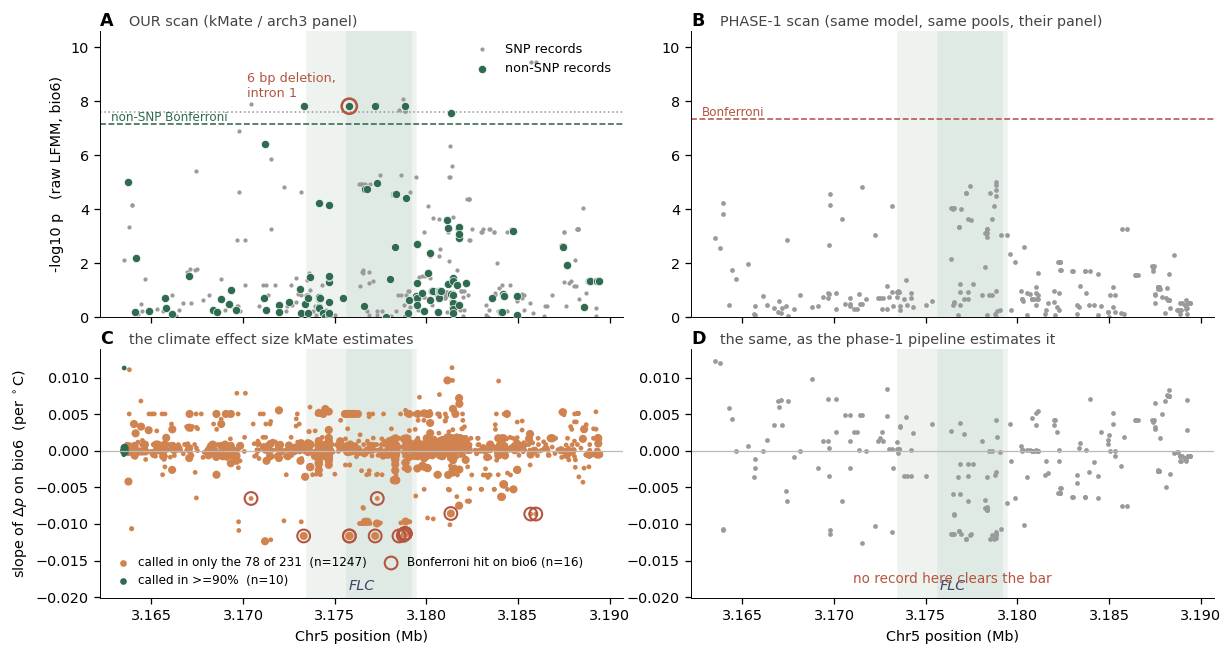

our scan, bio6: 22 records over the bar ({'snp': 10, 'nonsnp': 6, 'smallindel': 6}), best -log10 p = 9.45 (bar 7.15)
phase-1 scan: best -log10 p in the window = 5.01 on bio6 (bar 7.32) -> ZERO hits
phase-1 top axes here: {'bio7': 5.09, 'bio10': 5.04, 'bio6': 5.01}

call rate in the window: 99.2% at 78/231; the rest: [0.961, 0.965, 1.0]

coefficient on bio6: the 16 hits median -0.01133/degC vs +0.00014 for the rest; |coef| percentile of the hits: 98th (mean)
carriers among the called founders: median 2, range 1-105; the 16 hits: median 27

Bonferroni hits marked in C: 16 records ({'snp': 10, 'nonsnp': 6}); their mean Delta p -0.0520 vs +0.0001 for the rest (mean dp is NOT what is tested)

bio6 coefficient, the 227 SNPs both panels carry: kMate median -0.00019, phase-1 -0.00014, per-SNP correlation r = 0.940


In [2]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 6.4), sharex=True,
                       gridspec_kw=dict(wspace=0.13, hspace=0.12,
                                        height_ratios=[1.15, 1]))
o = R[(R.axis == "bio6")]
snp, ns = o[o.cls == "snp"], o[o.cls == "nonsnp"]
for a in ax.ravel():
    a.axvspan(*np.array(GENE)/1e6, color="#eef3f0", zorder=0)
    a.axvspan(*np.array(INTRON1)/1e6, color="#dfeae4", zorder=0)
for a in ax[1]:
    a.annotate("FLC", (np.mean(GENE)/1e6, 0.03), xycoords=("data", "axes fraction"),
               ha="center", fontsize=9, style="italic", color="#446")

# --- A/B: the p-values
ax[0, 0].scatter(snp.pos/1e6, snp.nlp, s=7, color=GREY, label="SNP records", linewidths=0)
ax[0, 0].scatter(ns.pos/1e6, ns.nlp, s=26, color=OURS, label="non-SNP records",
                 edgecolor="white", linewidths=0.4, zorder=3)
ax[0, 0].axhline(ns.bar.iloc[0], ls="--", lw=1, color=OURS)
ax[0, 0].axhline(snp.bar.iloc[0], ls=":", lw=1, color=GREY)
ax[0, 0].annotate("non-SNP Bonferroni", (0.02, ns.bar.iloc[0]),
                  xycoords=("axes fraction", "data"), fontsize=7.5, color=OURS, va="bottom")
lead = ns[ns.pos == FLCDEL]
if len(lead):
    ax[0, 0].scatter(lead.pos/1e6, lead.nlp, s=90, facecolor="none", edgecolor=ACCENT,
                     linewidths=1.6, zorder=4)
    ax[0, 0].annotate("6 bp deletion,\nintron 1", (lead.pos.iloc[0]/1e6, lead.nlp.iloc[0]),
                      xytext=(-64, 6), textcoords="offset points", fontsize=8, color=ACCENT)
ax[0, 0].set_ylabel("-log10 p   (raw LFMM, bio6)")
ax[0, 0].legend(frameon=False, fontsize=8, loc="upper right")
ax[0, 1].scatter(P1.pos/1e6, -np.log10(P1.bio6), s=9, color=GREY, linewidths=0)
ax[0, 1].axhline(-np.log10(P1.bonf.iloc[0]), ls="--", lw=1, color=PHASE1)
ax[0, 1].annotate("Bonferroni", (0.02, -np.log10(P1.bonf.iloc[0])),
                  xycoords=("axes fraction", "data"), fontsize=7.5, color=PHASE1, va="bottom")
ymax = max(o.nlp.max(), -np.log10(P1.bio6.min())) * 1.12
for a in ax[0]:
    a.set_ylim(0, ymax)

# --- C/D: the mean Delta p behind those p-values, with the Bonferroni hits marked
KEY = ["pos", "ref_len", "alt_len"]
hit_keys = set(map(tuple, o.loc[o.nlp > o.bar, KEY].drop_duplicates().to_numpy()))
TK["is_hit"] = [tuple(r) in hit_keys for r in TK[KEY].to_numpy()]
TK = TK.merge(W[KEY + ["call_rate", "n_carriers"]], on=KEY, how="left")
# colour by how many founders the variant is CALLED in -- the quantity this case is about.
# Binned, not a gradient: 99% of the window sits at exactly 78/231, so a continuous scale
# would be monochrome and hide the ten records that differ.
CRBIN = [("called in only the 78 of 231", lambda x: x < 0.50, "#d1834f"),
         ("called in 50-90%", lambda x: (x >= 0.50) & (x < 0.90), "#6f9fb8"),
         ("called in >=90%", lambda x: x >= 0.90, "#2f6b4f")]
for lab, f, col in CRBIN:
    q = TK[f(TK.call_rate)]
    if not len(q):
        continue
    ax[1, 0].scatter(q.pos/1e6, q.coef, s=np.where(q.kind == "nonsnp", 26, 9),
                     color=col, linewidths=0, zorder=2,
                     label=f"{lab}  (n={len(q)})")
H = TK[TK.is_hit]
ax[1, 0].scatter(H.pos/1e6, H.coef, s=64, facecolor="none", edgecolor=ACCENT,
                 linewidths=1.3, zorder=5, label=f"Bonferroni hit on bio6 (n={len(H)})")
ax[1, 0].legend(frameon=False, fontsize=7.5, loc="lower left", ncol=2,
                handletextpad=0.3, columnspacing=1.0)
ax[1, 1].scatter(TP.pos/1e6, TP.coef, s=9, color=GREY, linewidths=0)
ax[1, 1].annotate("no record here clears the bar", (0.5, 0.06), xycoords="axes fraction",
                  ha="center", fontsize=8.5, color=PHASE1)
lim = np.nanmax(np.abs(np.r_[TK.coef.values, TP.coef.values])) * 1.1
for a in ax[1]:
    a.axhline(0, color="#bbb", lw=0.8)
    a.set_ylim(-lim*1.45, lim); a.set_xlabel("Chr5 position (Mb)")
ax[1, 0].set_ylabel("slope of $\\Delta p$ on bio6  (per $^\\circ$C)")

for a, L, note in ((ax[0, 0], "A", "OUR scan (kMate / arch3 panel)"),
                   (ax[0, 1], "B", "PHASE-1 scan (same model, same pools, their panel)"),
                   (ax[1, 0], "C", "the climate effect size kMate estimates"),
                   (ax[1, 1], "D", "the same, as the phase-1 pipeline estimates it")):
    a.annotate(L, (0, 1.02), xycoords="axes fraction", fontweight="bold", fontsize=11)
    a.annotate(note, (0.055, 1.02), xycoords="axes fraction", fontsize=9, color="#444")
plt.savefig(f"{PLOTS}/locus.png", dpi=150, bbox_inches="tight"); plt.show()

sig = o[o.nlp > o.bar]
print(f"our scan, bio6: {len(sig)} records over the bar "
      f"({sig.cls.value_counts().to_dict()}), best -log10 p = {o.nlp.max():.2f} "
      f"(bar {ns.bar.iloc[0]:.2f})")
best_ax = (P1.drop(columns=['pos','bonf','n_tested']).min().sort_values().head(3))
print(f"phase-1 scan: best -log10 p in the window = {-np.log10(P1.bio6.min()):.2f} on bio6 "
      f"(bar {-np.log10(P1.bonf.iloc[0]):.2f}) -> ZERO hits")
print("phase-1 top axes here:", {k: round(-np.log10(v), 2) for k, v in best_ax.items()})
sh = TK[TK.kind == "snp"].merge(TP, on="pos", suffixes=("_kmate", "_phase1"))
print(f"\ncall rate in the window: {100*np.isclose(TK.call_rate, 78/231, atol=.002).mean():.1f}% "
      f"at 78/231; the rest: {sorted(TK.loc[~np.isclose(TK.call_rate, 78/231, atol=.002), 'call_rate'].round(3).unique())}")
print(f"\ncoefficient on bio6: the {int(TK.is_hit.sum())} hits median "
      f"{TK[TK.is_hit].coef.median():+.5f}/degC vs {TK[~TK.is_hit].coef.median():+.5f} for the rest; "
      f"|coef| percentile of the hits: {100*np.mean(TK.coef.abs().values[:,None] < TK[TK.is_hit].coef.abs().values).round(3):.0f}th (mean)")
print(f"carriers among the called founders: median {TK.n_carriers.median():.0f}, "
      f"range {int(TK.n_carriers.min())}-{int(TK.n_carriers.max())}; "
      f"the {int(TK.is_hit.sum())} hits: median {TK[TK.is_hit].n_carriers.median():.0f}")
print(f"\nBonferroni hits marked in C: {int(TK.is_hit.sum())} records "
      f"({TK[TK.is_hit].kind.value_counts().to_dict()}); "
      f"their mean Delta p {TK[TK.is_hit].mean_dp.mean():+.4f} vs "
      f"{TK[~TK.is_hit].mean_dp.mean():+.4f} for the rest (mean dp is NOT what is tested)")
print(f"\nbio6 coefficient, the {len(sh)} SNPs both panels carry: "
      f"kMate median {sh.coef_kmate.median():+.5f}, phase-1 {sh.coef_phase1.median():+.5f}, "
      f"per-SNP correlation r = {sh.coef_kmate.corr(sh.coef_phase1):.3f}")

**Where that leaves us — and the first surprise.** Our scan clears the bar by ~2 log
units on bio6; the phase-1 scan falls ~2.3 log units short of a bar that is *lower* than ours
(it tests half as many markers). The direction agrees: bio6/bio7/bio4, the same temperature
cluster, are the top axes at FLC in **both** scans.

Panel C confirms that the hits are not arbitrary — the 16 Bonferroni records sit at a median
slope of **−0.0113 per °C** against **+0.0001** for everything else in the window, the 98th
percentile of |coefficient|. They are the records whose frequency falls hardest as winters
get colder, and they are the common ones (median 27 carriers of the 78, against 2 for the
window at large).

**But compare C with D.** The phase-1 panel reaches the same coefficients — over the 227 SNPs
both panels carry, the two estimates of the bio6 slope correlate at **r = 0.94**. The two
pipelines agree almost exactly about *how strongly this haplotype responds to winter
temperature*. What they disagree about is how *cleanly* it does so: the same effect with
tighter scatter around it gives a smaller p-value, and that is the whole gap between 9.45 and
5.01. So the question is not "who sees a bigger effect" but **why our version of the same
effect looks less noisy** — which is what the rest of the notebook is about.

## 2 · What the difference is **not**

Four explanations can be ruled out with data rather than argument:

| candidate explanation | test | verdict |
|---|---|---|
| the SNPs aren't in the phase-1 panel | look them up | **all 10 are there**, and 617 catalogue SNPs sit in this window |
| they're too rare there to test | phase-1 founding frequencies | **common** — p0 MAF 0.22–0.45 |
| they're imputed guesses | the raw 1001 Genomes per-accession calls | **76% directly called**, ALT allele matching, 0/130 contradictions |
| phase-1's genotypes are wrong here | compare to the long-read assemblies, same 78 founders | **98.6% concordant** (background 99.1%) |
| our scan is just more inflated | genomic inflation on the same axis | **theirs is higher** — λ 1.99 vs our 1.81 |
| different samples or model | provenance | identical: `lfmm_ridge` K=16, 355 vs 352 last-gen pools |

So this is not ascertainment, not frequency, not imputation, not genotype error, not
calibration, and not the analysis. What is left is the **allele-frequency estimate itself**.

## 3 · First: the founder mixtures themselves agree

kMate works in two steps — infer each pool's **founder mixture** `h` from its *k*-mers, then
**project** that mixture through the panel's genotypes to get an allele frequency. A
disagreement with phase-1 could come from either step, and they have very different
implications: a wrong mixture would be a method problem, a wrong projection is a panel
problem.

Phase-1 estimates founder (ecotype) frequencies too, so the first step can be checked
directly against an independent pipeline, pool by pool, before touching FLC.

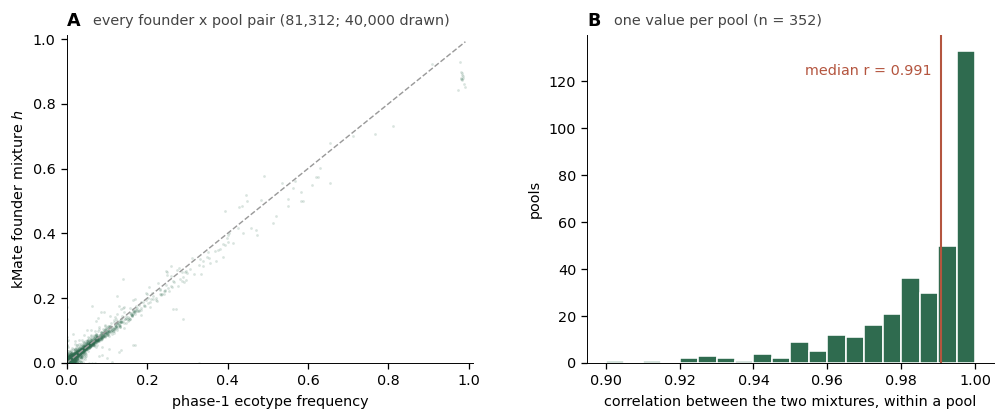

per-pool correlation between kMate h and phase-1 ecotype frequencies: median 0.991, 5th pct 0.926, min 0.565


In [3]:
HP = pd.read_csv(f"{CASE}/h_compare_pools.csv")
PR = pd.read_csv(f"{CASE}/h_compare_pairs.csv.gz")
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.7), gridspec_kw=dict(wspace=0.28))
sub = PR.sample(min(len(PR), 40000), random_state=0)
ax[0].scatter(sub.f_phase1, sub.h_kmate, s=3, color=OURS, alpha=0.18, linewidths=0)
m = max(sub.f_phase1.max(), sub.h_kmate.max())
ax[0].plot([0, m], [0, m], ls="--", lw=0.9, color=GREY)
ax[0].set_xlabel("phase-1 ecotype frequency"); ax[0].set_ylabel("kMate founder mixture $h$")
ax[0].set_xlim(0, m*1.02); ax[0].set_ylim(0, m*1.02)
ax[0].annotate("A", (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
ax[0].annotate(f"every founder x pool pair ({len(PR):,}; {len(sub):,} drawn)",
               (0.065, 1.03), xycoords="axes fraction", fontsize=9, color="#444")

ax[1].hist(HP.r, bins=np.arange(0.90, 1.001, 0.005), color=OURS, edgecolor="white")
ax[1].axvline(HP.r.median(), color=ACCENT, lw=1.3)
ax[1].annotate(f"median r = {HP.r.median():.3f}", (HP.r.median(), ax[1].get_ylim()[1]*0.88),
               xytext=(-6, 0), textcoords="offset points", ha="right", fontsize=9, color=ACCENT)
ax[1].set_xlabel("correlation between the two mixtures, within a pool")
ax[1].set_ylabel("pools")
ax[1].annotate("B", (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
ax[1].annotate(f"one value per pool (n = {len(HP)})", (0.065, 1.03),
               xycoords="axes fraction", fontsize=9, color="#444")
plt.savefig(f"{PLOTS}/h_agreement.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"per-pool correlation between kMate h and phase-1 ecotype frequencies: "
      f"median {HP.r.median():.3f}, 5th pct {HP.r.quantile(.05):.3f}, min {HP.r.min():.3f}")

**The mixtures agree** — median r = 0.99 across the 352 pools, and the two pipelines
place the same founders at the same frequencies throughout. Step one is not the problem.
Whatever happens at FLC therefore happens in **step two, the projection**, which is exactly
where the panel enters.

## 4 · The decisive test

Everything so far is circumstantial: the frequency *could* be fine despite resting on a third
of the panel. The way to find out is to remove the difference and see what happens to the
signal.

**The experiment.** Take kMate's own inferred founder mixtures `h` — production values,
unchanged — and substitute the 153 missing founders' genotypes from the phase-1 panel, so the
same projection runs over all 231 instead of 78. Nothing else changes: same pools, same `h`,
same arithmetic. Three estimates of Δp at the 10 shared SNPs:

| | what it is |
|---|---|
| **kMate (production)** | the projection over the 78 called founders |
| **filled** | kMate's *own* `h`, genotypes for all 231 |
| **hapFIRE** | the phase-1 pipeline's own estimate, computed independently |

If the 78-founder restriction is incidental, *filled* should look like *kMate*. If the
restriction is the signal, *filled* should collapse onto *hapFIRE*.

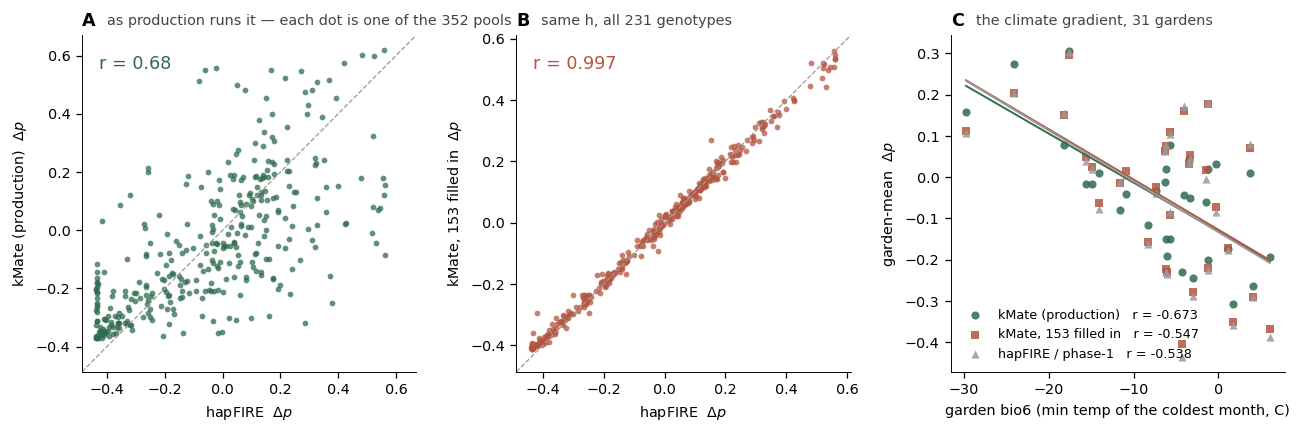

               estimate  r_vs_hapfire_pool  garden_r garden_p
 kMate (production, 78)              0.679    -0.673  3.3e-05
kMate, 153 filled (231)              0.997    -0.547  1.5e-03
      hapFIRE / phase-1              1.000    -0.538  1.8e-03

mean over all 10 SNPs:  kMate-vs-hapFIRE r = 0.664   |   filled-vs-hapFIRE r = 0.997


In [4]:
snps = D["snps"]; site = D["site"]; bio6 = D["bio6"]
K, F, Hf = D["kmate"], D["filled"], D["hapfire"]
j = list(snps).index(3178515)                      # the tag SNP in perfect LD with the indel
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.8), gridspec_kw=dict(wspace=0.3))

ax[0].scatter(Hf[:, j], K[:, j], s=13, color=OURS, alpha=0.75, linewidths=0)
r0 = pearsonr(Hf[:, j], K[:, j])[0]
ax[0].set_xlabel("hapFIRE  $\\Delta p$"); ax[0].set_ylabel("kMate (production)  $\\Delta p$")
ax[0].annotate(f"r = {r0:.2f}", (0.05, 0.9), xycoords="axes fraction", fontsize=11, color=OURS)
ax[0].annotate("A", (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
ax[0].annotate("as production runs it — each dot is one of the 352 pools",
               (0.075, 1.03), xycoords="axes fraction", fontsize=9, color="#444")

ax[1].scatter(Hf[:, j], F[:, j], s=13, color=ACCENT, alpha=0.75, linewidths=0)
r1 = pearsonr(Hf[:, j], F[:, j])[0]
ax[1].set_xlabel("hapFIRE  $\\Delta p$"); ax[1].set_ylabel("kMate, 153 filled in  $\\Delta p$")
ax[1].annotate(f"r = {r1:.3f}", (0.05, 0.9), xycoords="axes fraction", fontsize=11, color=ACCENT)
ax[1].annotate("B", (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
ax[1].annotate("same h, all 231 genotypes", (0.075, 1.03), xycoords="axes fraction",
               fontsize=9, color="#444")
for a in (ax[0], ax[1]):
    lim = [min(a.get_xlim()[0], a.get_ylim()[0]), max(a.get_xlim()[1], a.get_ylim()[1])]
    a.plot(lim, lim, ls="--", lw=0.8, color=GREY); a.set_xlim(*lim); a.set_ylim(*lim)

def garden(v):
    s = pd.Series(v, index=site).groupby(level=0).mean()
    x = pd.Series(bio6, index=site).groupby(level=0).first()
    return x.values, s.values
for lab, M, col, mk in (("kMate (production)", K, OURS, "o"),
                        ("kMate, 153 filled in", F, ACCENT, "s"),
                        ("hapFIRE / phase-1", Hf, GREY, "^")):
    x, y = garden(M[:, j])
    r = pearsonr(x, y)[0]
    ax[2].scatter(x, y, s=26, color=col, marker=mk, alpha=0.85, linewidths=0,
                  label=f"{lab}   r = {r:+.3f}")
    b, a0 = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 10)
    ax[2].plot(xs, a0 + b*xs, color=col, lw=1.2)
ax[2].set_xlabel("garden bio6 (min temp of the coldest month, C)")
ax[2].set_ylabel("garden-mean  $\\Delta p$")
ax[2].legend(frameon=False, fontsize=8, loc="lower left")
ax[2].annotate("C", (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
ax[2].annotate("the climate gradient, 31 gardens", (0.075, 1.03), xycoords="axes fraction",
               fontsize=9, color="#444")
plt.savefig(f"{PLOTS}/decisive_test.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for nm, M in (("kMate (production, 78)", K), ("kMate, 153 filled (231)", F),
              ("hapFIRE / phase-1", Hf)):
    x, y = garden(M[:, j])
    r, p = pearsonr(x, y)
    rows.append(dict(estimate=nm, r_vs_hapfire_pool=round(pearsonr(M[:, j], Hf[:, j])[0], 3),
                     garden_r=round(r, 3), garden_p=f"{p:.1e}"))
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nmean over all {len(snps)} SNPs:  kMate-vs-hapFIRE r = "
      f"{np.mean([pearsonr(K[:,k],Hf[:,k])[0] for k in range(len(snps))]):.3f}   |   "
      f"filled-vs-hapFIRE r = {np.mean([pearsonr(F[:,k],Hf[:,k])[0] for k in range(len(snps))]):.3f}")

**The answer.** Filling in the missing genotypes makes kMate agree with hapFIRE at
**r ≈ 0.997** — they become the same estimate. As production runs it, the agreement is only
**r ≈ 0.66**. Every other component is therefore exonerated: kMate's founder mixtures are
right, hapFIRE's pool estimation is right, and the two pipelines agree almost perfectly at
this locus **when both see the same genotypes**.

And the climate gradient moves the way that matters. Across the 31 gardens:

| estimate | r with bio6 | p |
|---|---|---|
| kMate as production runs it (78 founders) | **−0.673** | 3.3e−05 |
| kMate, 153 filled in (231 founders) | −0.547 | 1.5e−03 |
| hapFIRE / phase-1 | −0.538 | 1.8e−03 |

(those are for the tag SNP plotted in panel C; averaged over all ten shared SNPs the same
three numbers are −0.668, −0.574 and −0.561.)

**The restriction to 78 founders is what makes the association strong enough to clear a
genome-wide threshold.** With the full panel, kMate's own estimate lands essentially on
phase-1's.

Note what this does *not* say. All three estimates show a real gradient in the expected
direction — the allele declines where winters are colder, at p ≈ 1e−3 across gardens. FLC may
well be under climate selection; the literature certainly thinks so. What the test shows is
that **the genome-wide significance in our scan is produced by the restricted denominator**,
so the honest effect size here is phase-1's, not ours — and we should not report FLC as a
discovery our panel made and theirs missed.

## 5 · How often does this happen? — and the filter it implies

FLC is one locus. The question for the rest of the analysis is whether records genotyped in
few founders are *systematically* more likely to clear the threshold. Measured genome-wide
**within MAF strata**, so this is not frequency confounding:

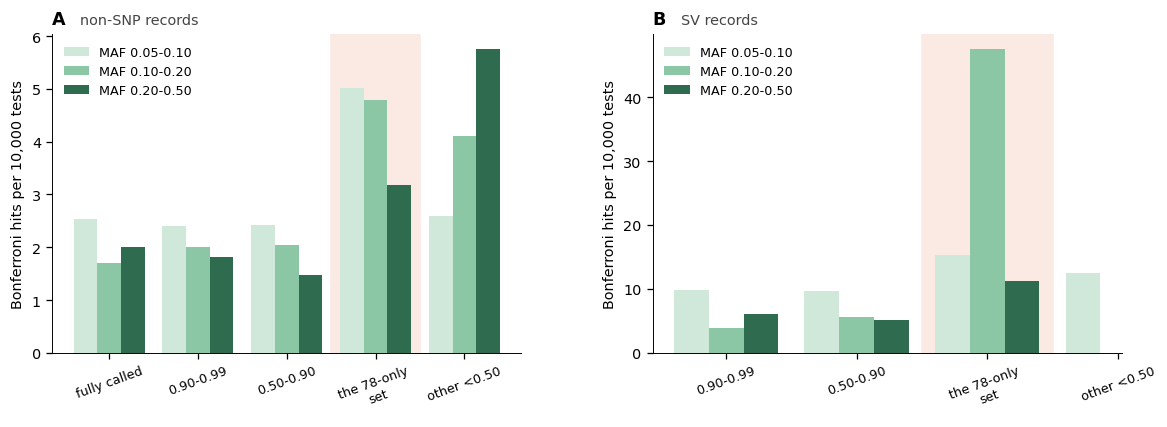

nonsnp: 4,456 hits, ~517 excess in the low-call strata (11.6% of the hit list)
sv: 2,018 hits, ~443 excess in the low-call strata (22.0% of the hit list)


In [5]:
CAL = pd.read_csv(f"{G}/r2_gea_nonsnp/phase1_replication/results/multiaxis/callrate_calibration.csv")
ORDER = ["fully called", "0.90-0.99", "0.50-0.90", "the 78-only set", "other <0.50"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(wspace=0.28))
for k, (cls, a) in enumerate(zip(["nonsnp", "sv"], ax)):
    S = CAL[CAL.cls == cls]
    mafs = sorted(S.maf.unique()); w = 0.8/len(mafs)
    for i, mb in enumerate(mafs):
        z = S[S.maf == mb].groupby("strat")[["hits", "n"]].sum()
        t = (1e4 * z.hits / z.n).reindex(ORDER)
        xs = np.arange(len(ORDER)) + (i - (len(mafs)-1)/2)*w
        a.bar(xs, t.values, w, color=["#cfe8da", "#8cc7a5", "#2f6b4f"][i], label=f"MAF {mb}")
    a.set_xticks(range(len(ORDER)))
    a.set_xticklabels([o.replace(" set", "\nset") for o in ORDER], fontsize=8, rotation=20)
    a.set_ylabel("Bonferroni hits per 10,000 tests")
    a.annotate("AB"[k], (0, 1.03), xycoords="axes fraction", fontweight="bold", fontsize=11)
    a.annotate({"nonsnp": "non-SNP records", "sv": "SV records"}[cls], (0.06, 1.03),
               xycoords="axes fraction", fontsize=9, color="#444")
    a.legend(frameon=False, fontsize=8)
    lo = ORDER.index("the 78-only set")
    a.axvspan(lo-0.5, lo+0.5, color="#fbe9e4", zorder=0)
plt.savefig(f"{PLOTS}/calibration.png", dpi=150, bbox_inches="tight"); plt.show()

for cls in ["nonsnp", "sv"]:
    S = CAL[CAL.cls == cls]
    z = S[S.strat.isin(["fully called", "0.90-0.99", "0.50-0.90"])].groupby("maf")[["hits", "n"]].sum()
    ref = 1e4 * z.hits / z.n
    exc = 0
    for st in ["the 78-only set", "other <0.50"]:
        g = S[S.strat == st]
        if len(g):
            exc += g.hits.sum() - sum(ref.get(m, np.nan)*n/1e4
                                      for m, n in g.groupby("maf")["n"].sum().items())
    print(f"{cls}: {S.hits.sum():,} hits, ~{int(exc):,} excess in the low-call strata "
          f"({100*exc/S.hits.sum():.1f}% of the hit list)")

**Reading it.** Within every frequency band and in both classes, the **78-only
stratum** (shaded) produces roughly **twice** the non-SNP hit rate of well-called records and
up to **12×** for SVs, with λ inflated from ~1.7–1.8 to ~2.1–2.3. Records between 0.50 and
0.90 call rate are indistinguishable from fully-called ones — so this is not a smooth
degradation with call rate, it is a cliff at the bottom.

Scoring the low-call strata against the well-called hit rate at the same MAF puts the excess
at roughly **12% of the non-SNP hit list and 22% of the SV hit list**. That is not proof that
any particular one of them is false — but FLC is a confirmed member, and it is the size of the
contamination.

### What follows

A **call-rate floor of 0.50**, applied beside the MAF filter before any threshold is computed.
It removes exactly the miscalibrated strata (78/231 = 0.338 falls below it) at a cost of 12%
of non-SNP and 19% of SV tests. A stricter floor of 0.90 would cost **56% of non-SNP and 82%
of SV tests** to remove records that measure as well calibrated — and no SV record at all
survives 0.99.

The candidate list should be **re-derived** under that floor rather than audited locus by
locus, since ~12–22% of it comes from the affected strata.